# このノートブックの使い方

コードの中にある `___`（アンダーバー3つ）の部分は、空欄になっています。

スライドを見ながら、`___` を正しい言葉に書きかえてから、セルを実行しましょう。

- 空欄のある行には、`# ←` で何を入れるかのヒントが書いてあります。

- `___` のまま実行すると、エラーになります。

- セルは **上から順番に** 実行しましょう。

# 1. データ分析の準備：必要な道具（ライブラリ）を読み込もう！

データ分析では、ライブラリという便利なプログラムの道具を組み合わせて使います。  

このような道具を **ライブラリ** といいます。

今回は、

- データを読み込んだり整理したりするためのもの

- モデルを作るためのもの

- 予測の結果を確かめるためのもの

を読み込みます。

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# 2. 分析するデータを読み込もう！

データ分析を始めるには、まず分析に使うデータが必要です。  

今回は、家の価格を予測するために、次の2つのデータを使います。

- `train.csv`  

  予測のルールを学ぶためのデータです。  

  家の情報と、実際の売値 `SalePrice` が入っています。

- `test.csv`  

  学んだルールを使って価格を予測するためのデータです。  

  こちらには売値 `SalePrice` は入っていません。

まずはデータを読み込み、最初の数行を見て、どのような情報が入っているかを確認します。

In [ ]:
PATH = 'https://raw.githubusercontent.com/Toyoda05/kaggle-house-price-practice/main/'
#trainデータを読み込みtrainとする
___ = pd.read_csv(PATH + 'train.csv')  # ← 学習データを入れる変数の名前
#testデータを読み込みtestとする
___ = pd.read_csv(PATH + 'test.csv')  # ← テストデータを入れる変数の名前

print("学習データ最初の5行:")
print(train.head())
print("テストデータ最初の5行:")
print(test.head())

# 3. 予測したいもの（目的変数）と予測に使う情報（説明変数）を分けよう！

ここでは、**何を予測したいのか** と、**その予測に使う情報は何か** を分けます。

- **目的変数（y）**  

  予測したい答えです。今回は **家の売値 `SalePrice`** です。  

  今回は扱いやすくするために、少し変換して使います。

- **説明変数（X, X_test）**  

  予測のヒントになる情報です。  

  たとえば、家の広さや部屋数、築年数などが入っています。

学習データから `SalePrice` を取り除いたものを `X`、  

テストデータを `X_test` として使います。

In [ ]:
#trainデータの目的変数をyとしてみよう！
___ = train["___"]  # ← 目的変数を入れる変数の名前と、目的変数の列名

#yの最初の5行を表示
print(y.head())

# 目的変数の対数変換（詳細は第二回で解説）
y = np.log1p(y)

In [ ]:
# trainデータから目的変数を除外して、説明変数をXとする。
___ = train.drop(columns=["___"])  # ← 説明変数を入れる変数の名前と、目的変数の列名

# テストデータはそのままX_testとする
___ = test.copy()  # ← テストデータの説明変数を入れる変数の名前

print(f"X_testの(行,列): {X_test.shape}")
print(f"Xの(行,列): {X.shape}")

# 4. 学習用データとテスト用データを一度まとめよう！

この後、データに同じ前処理をしたいので、学習用データ `X` とテスト用データ `X_test` を一度まとめます。

こうしておくと、

- 同じルールでまとめて加工できる

- 列のずれなどが起きにくい

というメリットがあります。

ここでは、2つのデータを縦につなげて `all_data` という1つのデータにします。

In [ ]:
# trainとtestデータを結合して一括前処理を行う
all_data = pd.concat([___, ___], axis=0).reset_index(drop=True)  # ← まとめる2つのデータ

print(f"結合前のXの(行,列): {X.shape}")
print(f"結合前のX_testの(行,列): {X_test.shape}")
print(f"結合後の全データの(行,列): {all_data.shape}")

# 5. 数字のデータと文字のデータを分けよう！

データには、大きく分けて2種類あります。

- **数値データ**  

  数字で表されるデータです。  

  例：家の広さ、築年数、部屋数

- **カテゴリデータ**  

  種類や名前を表すデータです。  

  例：家のタイプ、外壁の種類

この後の前処理では、数字の列と文字の列でやることが違うので、ここで分けておきます。

In [ ]:
# 数値列とカテゴリ（文字列）列を区別する
___ = all_data.select_dtypes(include=["int64", "float64"]).columns  # ← 数値列を入れる変数の名前
___ = all_data.select_dtypes(include=["object"]).columns  # ← カテゴリ列を入れる変数の名前

print(f"数値列の数: {len(numeric_cols)}")
print(f"カテゴリ列の数: {len(categorical_cols)}")

# 6. 数字のデータにある空欄を埋めよう！

データの中には、値が入っていない **空欄（欠損値）** があることがあります。

そのままでは計算できないので、まずは空欄を埋めます。  

今回は、数値データの空欄を **中央値** で埋めます。

中央値は、値を小さい順に並べたときに真ん中にくる値です。  

極端に大きい値や小さい値の影響を受けにくいので、よく使われます。

In [ ]:
print(f"数値列の補完後の欠損値の総数: {all_data[numeric_cols].isnull().sum().sum()}")

# 数値列の欠損値を中央値で埋める
for col in ___:  # ← 数値列の一覧
  all_data[col] = all_data[col].fillna(all_data[col].median())

print("\n数値列の欠損値を中央値で補完しました。")
print(f"数値列の補完後の欠損値の総数: {all_data[numeric_cols].isnull().sum().sum()}")

# 7. 文字のデータにある空欄を埋めよう！

文字のデータにも空欄があることがあります。

文字データの場合は、今回は `"Missing"` という値で埋めます。  

こうすることで、「値が入っていなかった」という情報も1つの特徴として残すことができます。

In [ ]:
# カテゴリ列の欠損値を"Missing"で埋める
for col in ___:  # ← カテゴリ列の一覧
  all_data[col] = all_data[col].fillna(___)  # ← 空欄を埋める文字（"" で囲む）

print("\nカテゴリ列の欠損値を'Missing'で補完しました。")
print(all_data["PoolQC"].head())

# 8. 文字のデータを数字に変えよう！

機械に学習させるとき、文字をそのまま使うことができません。  

そのため、文字のデータを数字に変換する必要があります。

ここでは、カテゴリごとに列を分けて、当てはまるときだけ `1`、そうでないときは `0` を入れる方法を使います。

こうすることで、文字の情報も機械学習で使えるようになります。

In [ ]:
print(f"ワンホットエンコーディング前の全データの（行,列）: {all_data.shape}")

# カテゴリ列（文字列）を数値に変換する
all_data = pd.get_dummies(all_data, drop_first=True)

print("\nカテゴリ列をワンホットエンコーディングしました。")
print(f"ワンホットエンコーディング後の全データの（行,列）: {all_data.shape}")

# 9. 加工したデータを元の学習用とテスト用に分け直そう！

ここまでで、学習用データとテスト用データをまとめて前処理してきました。

でも、実際に学習に使うのは元の学習用データの部分だけで、  

予測に使うのは元のテスト用データの部分だけです。

そこでここでは、前処理した `all_data` を

- `X_processed`

- `X_test_processed`

の2つに分け直します。

In [ ]:
# 前処理したデータを元のtrainとtestの形式に戻す
___ = all_data.iloc[:len(X)].copy()  # ← 前処理した学習データを入れる変数の名前
___ = all_data.iloc[len(X):].copy()  # ← 前処理したテストデータを入れる変数の名前

print("\n前処理済みデータをX_processedとX_test_processedに分割しました。")
print(f"all_dataの（行,列): {all_data.shape}")
print(f"X_processedの（行,列): {X_processed.shape}")
print(f"X_test_processedの（行,列): {X_test_processed.shape}")

# 10. 学習用データをさらに学習用と確認用に分けよう！

モデルがちゃんと予測できるかを確かめるために、学習用データをさらに2つに分けます。

- **学習用データ**  

  ルールを学ぶために使うデータ

- **確認用データ**  

  学んだルールが、初めて見るデータにも通用するかを確かめるためのデータ

今回は、学習用80%、確認用20%に分けます。

In [ ]:
# 学習データと検証データに分割する
___, ___, ___, ___ = train_test_split(  # ← 学習用・確認用に分けたデータの名前（4つ）
  X_processed, y, test_size=0.2, random_state=42
)
print("\nデータを学習用と検証用に分割しました。")
print(f"X_trainの形状: {X_train.shape}")
print(f"X_validの形状: {X_valid.shape}")
print(f"y_trainの形状: {y_train.shape}")
print(f"y_validの形状: {y_valid.shape}")

# 11. 線形回帰モデルを学習させよう！

ここでは **線形回帰（Linear Regression）** という方法を使います。

線形回帰は、データの関係をもとに予測を行う、基本的な機械学習モデルの1つです。  

まずはこの方法で、家の情報から価格を予測できるように学習させます。

In [ ]:
# 線形回帰モデルの初期化と学習
model = LinearRegression()
model.fit(___, ___)  # ← 説明変数と目的変数
print("\n線形回帰モデルを初期化し、学習を完了しました。")

# 12. 確認用データで予測してみよう！

学習が終わったら、次は確認用データを使って予測してみます。

ここでは、学習のときには使っていないデータに対して予測を行い、  

どのくらいうまく予測できるかを見ていきます。

In [ ]:
# 検証データでの予測
valid_pred = model.predict(___)  # ← 検証データの説明変数
print("\n検証データでの予測を行いました。")

# 13. 予測の結果を評価しよう！

予測した値が、実際の値とどのくらい近いかを確かめます。

ここでは **RMSE** という指標を使います。  

RMSE は、予測のずれの大きさを表す数値で、**小さいほど良い予測** だと考えます。

In [ ]:
# 検証データでのRMSE（二乗平均平方根誤差）の計算と表示
rmse = np.sqrt(mean_squared_error(y_valid, valid_pred))
print("RMSE:", rmse)

# 14. テストデータの価格を予測しよう！

モデルの動きを確認できたら、最後に `test.csv` の家の価格を予測します。

このデータには答えが入っていないので、  

ここで出した予測結果が、最終的に提出する答えになります。

In [ ]:
test_pred = model.predict(___)  # ← 予測したいテストデータの説明変数
print("\nテストデータでの予測を行いました。")

# 15. 提出用ファイルを作ろう！

最後に、予測結果を提出できる形にまとめます。

今回は、`Id` と予測した `SalePrice` を入れた表を作り、  

ファイルとして保存します。

また、最初に価格を変換していたので、ここで元に戻してから保存します。

In [ ]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": np.expm1(test_pred)
})

submission.to_csv("submission.csv", index=False)
print("\n提出用ファイル 'submission.csv' を作成しました。")
print("提出用ファイルの最初の5行:")
print(submission.head())

# 16. モデルを変えてみよう！

ここまでで、データの準備から提出用ファイルの作成まで、一通りの流れを体験しました。

ここからは、**モデルだけを別のものに変える** と予測がどう変わるかを試してみます。

今回使うのは **ランダムフォレスト（Random Forest）** です。

- **ランダムフォレスト**：<br>少しずつ違う**決定木**をたくさん作り、それぞれの予測を平均して答えを出すモデルです。


- **決定木**：<br>
質問を重ねて家をグループに分け、そのグループの平均価格を予測にするモデルです。  

  たとえば、`train.csv` の1,460軒を次のように分けることができます。

  1. 「敷地面積は 10,924 sqft 以下？」→ はいの1,005軒は、平均 **約15.9万ドル**

  2. いいえの455軒を「建築年は1988年以前？」で分ける → はいの250軒は平均 **約18.3万ドル**、いいえの205軒は平均 **約28.8万ドル**

  敷地 11,250 sqft・2001年築の家なら、どちらも「いいえ」に進むので、予測は **約28.8万ドル** になります。  

  10,924 や 1988 といった境目は人が決めるのではなく、データから自動で見つけます。
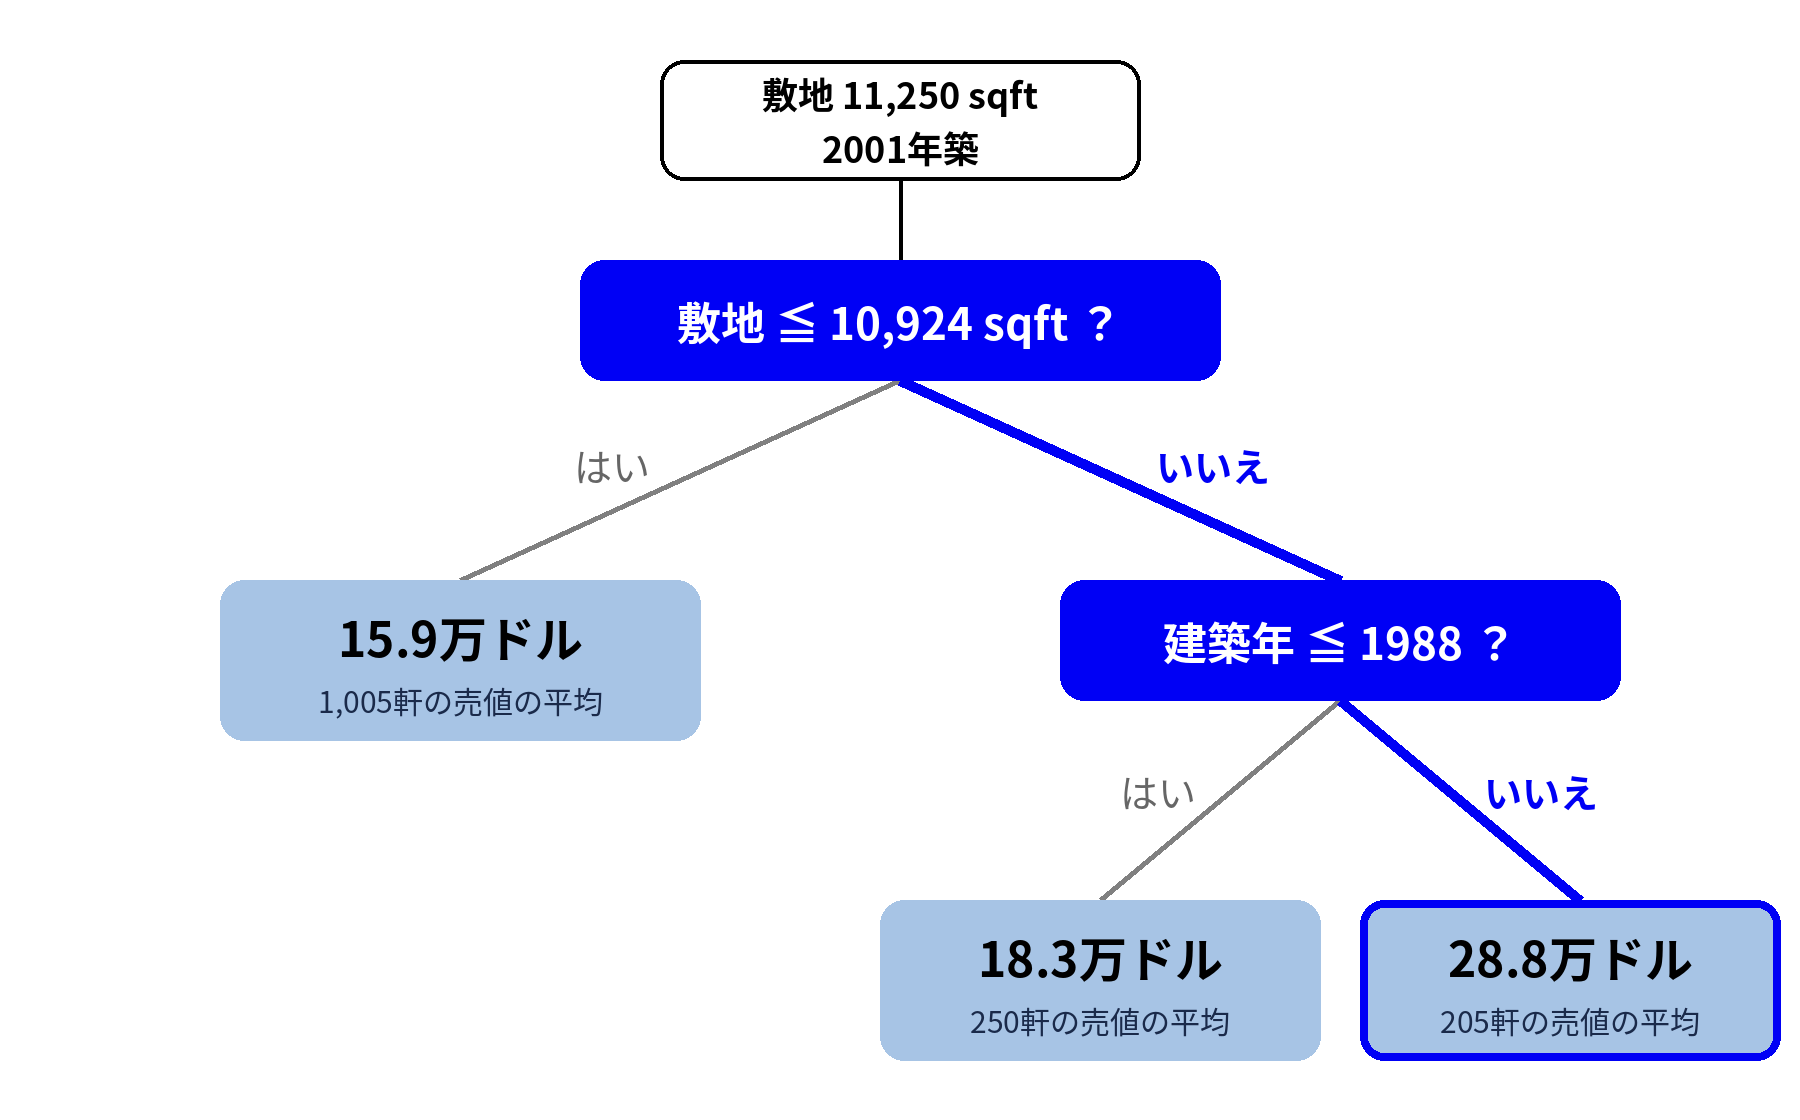

1本の木だけだと予測がかたよりやすいですが、たくさんの木の意見をまとめることで、安定した予測ができます。

データの前処理や、学習用・確認用の分け方は **これまでと同じもの** をそのまま使います。  

変えるのは、モデルを用意する部分だけです。

# 17. ランダムフォレストを学習させよう！

線形回帰のときと比べて、変わるのは次の2か所だけです。

- 読み込む道具：`LinearRegression` → `RandomForestRegressor`

- モデルの用意：`LinearRegression()` → `RandomForestRegressor(...)`

かっこの中の設定の意味は次のとおりです。

- `n_estimators=300`：作る木の本数です。今回は300本にします。

- `random_state=42`：毎回同じ結果になるように、乱数を固定するための数字です。

- `n_jobs=-1`：パソコンの力をすべて使って、速く計算するための設定です。

学習のさせ方は線形回帰と同じで、`fit` を使います。

In [ ]:
# ランダムフォレストを使うための道具を読み込む
from sklearn.ensemble import RandomForestRegressor

# ランダムフォレストモデルの初期化と学習
rf_model = ___(n_estimators=300, random_state=42, n_jobs=-1)  # ← 使うモデルの名前
rf_model.fit(___, ___)  # ← 説明変数と目的変数
print("\nランダムフォレストモデルを初期化し、学習を完了しました。")

# 18. ランダムフォレストの中の木をのぞいてみよう！

ランダムフォレストは、たくさんの決定木の集まりでした。  

ここでは、300本のうち **1本目の木** の上の部分を図にして、実際にどんな質問をしているかを見てみます。

- `rf_model.estimators_[0]`：300本のうち1本目の木です。`[1]` にすると2本目の木になります。

- `max_depth=2`：上から2段目の質問までを表示します。実際の木はとても深いので、全部を表示すると読めなくなります。

図の見方は次のとおりです。

- 1行目：質問です。たとえば `OverallQual <= 6.5` は「品質は6.5以下？」という意味で、**はいなら左、いいえなら右** に進みます。

- `samples`：そこに入った家の数です。

- `value`：そこに入った家の価格の平均です。価格は対数に変換しているので、ドルの金額ではありません。

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# 1本目の木を取り出す
first_tree = rf_model.estimators_[0]

print("この木の深さ（質問の段数）:", first_tree.get_depth())
print("最後のグループの数:", first_tree.get_n_leaves())

# 上から2段目までを図にする
plt.figure(figsize=(20, 8))
plot_tree(
    first_tree,
    max_depth=2,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    impurity=False,
    precision=2,
    fontsize=11
)
plt.show()

# 19. 2つのモデルの予測を比べよう！

線形回帰のときと同じ確認用データで予測し、同じ **RMSE** で評価します。

同じデータ・同じ指標で比べるので、RMSE の差は **モデルの違い** によるものだと考えられます。

RMSE は **小さいほど良い予測** でしたね。どちらのモデルが良いか見てみましょう。

In [ ]:
# 検証データでの予測（ランダムフォレスト）
rf_valid_pred = rf_model.predict(X_valid)

# 検証データでのRMSEの計算
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_valid_pred))

print("線形回帰のRMSE:", rmse)
print("ランダムフォレストのRMSE:", rf_rmse)

# 20. ランダムフォレストの予測で提出用ファイルを作ろう！

最後に、ランダムフォレストでも `test.csv` の家の価格を予測して、提出用ファイルを作ります。

線形回帰のファイルと区別できるように、`submission_rf.csv` という名前で保存します。

In [ ]:
# テストデータでの予測（ランダムフォレスト）
rf_test_pred = rf_model.predict(X_test_processed)

submission_rf = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": np.expm1(rf_test_pred)
})

submission_rf.to_csv("submission_rf.csv", index=False)
print("\n提出用ファイル 'submission_rf.csv' を作成しました。")
print("提出用ファイルの最初の5行:")
print(submission_rf.head())